In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import lightgbm as lgb
from catboost import CatBoostRegressor, Pool
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
from sklearn.linear_model import ElasticNet
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import OneHotEncoder

import gc
import warnings
warnings.filterwarnings("ignore")

In [ ]:
oil = pd.read_csv("/kaggle/input/store-sales-time-series-forecasting/oil.csv", parse_dates=['date'])
sample_submission = pd.read_csv("/kaggle/input/store-sales-time-series-forecasting/sample_submission.csv")
holidays = pd.read_csv("/kaggle/input/store-sales-time-series-forecasting/holidays_events.csv", parse_dates=['date'])
stores = pd.read_csv("/kaggle/input/store-sales-time-series-forecasting/stores.csv")
train = pd.read_csv("/kaggle/input/store-sales-time-series-forecasting/train.csv", parse_dates=['date'])
test = pd.read_csv("/kaggle/input/store-sales-time-series-forecasting/test.csv", parse_dates=['date'])
transactions = pd.read_csv("/kaggle/input/store-sales-time-series-forecasting/transactions.csv", parse_dates=['date'])

In [ ]:
# --- Bắt đầu lọc dữ liệu ---
print("Bắt đầu lọc dữ liệu để chỉ giữ lại năm 2017...")

# 1. Lọc bảng train
print(f"\nBảng train ban đầu có {len(train)} dòng.")
train_2017 = train[train['date'].dt.year == 2017].copy()
print(f"Bảng train sau khi lọc còn {len(train_2017)} dòng.")

# 2. Lọc bảng test
# Tập test hoàn toàn nằm trong năm 2017 nên không cần lọc, nhưng kiểm tra để chắc chắn
print(f"\nBảng test ban đầu có {len(test)} dòng.")
test_2017 = test[test['date'].dt.year == 2017].copy()
print(f"Bảng test sau khi lọc còn {len(test_2017)} dòng.")

# 3. Lọc bảng oil
start_date_filter = '2016-12-30'
print(f"\nBảng oil ban đầu có {len(oil)} dòng.")
oil_2017 = oil[oil['date'] >= start_date_filter].copy()
print(f"Bảng oil sau khi lọc còn {len(oil_2017)} dòng.")

# 4. Lọc bảng holidays_events
print(f"\nBảng holidays_events ban đầu có {len(holidays)} dòng.")
holidays_2017 = holidays[holidays['date'].dt.year == 2017].copy()
print(f"Bảng holidays_events sau khi lọc còn {len(holidays_2017)} dòng.")

# 5. Lọc bảng transactions
print(f"\nBảng transactions ban đầu có {len(transactions)} dòng.")
transactions_2017 = transactions[transactions['date'].dt.year == 2017].copy()
print(f"Bảng transactions sau khi lọc còn {len(transactions_2017)} dòng.")

print("\nĐã hoàn thành! Các DataFrame mới (ví dụ: train_2017) đã sẵn sàng cho các bước tiếp theo.")

# (Tùy chọn) Hiển thị 5 dòng đầu của một trong các bảng đã lọc để kiểm tra
print("\nVí dụ 5 dòng đầu của bảng train_2017:")
display(train_2017.head())

# A. Mergring Data

## 1. Phân tích bộ train và stores

In [ ]:
train_2017.info()

In [ ]:
train_2017.nunique()

## Merge bộ train và test với bộ stores

In [ ]:
df_train_store = pd.merge(train_2017, stores, on="store_nbr", how="left")
df_test_store = pd.merge(test_2017, stores, on="store_nbr", how="left")

In [ ]:
df_train_store

## 2. Phân tích bộ oil

In [ ]:
oil_2017.info()

In [ ]:
oil_2017.head(10)

## Thêm các ngày thứ bảy và chủ nhật để dữ liệu của cột date trở nên liên tục.

In [ ]:
# 1. Tạo dãy ngày liên tục từ min đến max
full_dates = pd.date_range(start=oil_2017['date'].min(), end=oil_2017['date'].max())

# 2. Set index là 'date' để reindex
oil_2017 = oil_2017.set_index('date')

# 3. Reindex để thêm các ngày bị thiếu (cuối tuần)
oil_2017 = oil_2017.reindex(full_dates)

# 4. Đổi tên lại index thành 'date'
oil_2017.index.name = 'date'

# 5. Điền giá trị thiếu bằng giá trị gần nhất trước đó
oil_2017['dcoilwtico'] = oil_2017['dcoilwtico'].ffill()

# 6. Reset index nếu muốn dùng kiểu dataframe thông thường
oil_2017 = oil_2017.reset_index()

In [ ]:
oil_2017.head(10)

In [ ]:
oil_2017.info()

In [ ]:
##### KIỂM TRA XEM DỮ LIỆU NGÀY CỦA DF_TRAIN_STORE CÓ LIÊN TIẾP KHÔNG
# 1. Lấy các giá trị date độc nhất
unique_dates = df_train_store['date'].drop_duplicates()

# 2. Sắp xếp lại các giá trị date
unique_dates_sorted = unique_dates.sort_values()

# 3. Tính sự chênh lệch giữa các ngày liên tiếp
date_diff = unique_dates_sorted.diff()

# 4. Kiểm tra xem có ngày nào cách nhau không phải 1 ngày
missing_dates = unique_dates_sorted[date_diff != pd.Timedelta(days=1)]

# 5. In kết quả
if missing_dates.empty:
    print("Tất cả các ngày độc nhất đều liên tiếp.")
else:
    print("Có ngày không liên tiếp")


In [ ]:
df_train_store.nunique()

## Merge df_train_store df_test_store và oil

In [ ]:
df_train_store_oil = pd.merge(df_train_store, oil_2017, on="date", how="left")
df_test_store_oil = pd.merge(df_test_store, oil_2017, on="date", how="left")

df_train_store_oil

In [ ]:
df_train_store_oil.info()

In [ ]:
df_test_store_oil.info()

## 3. Phân tích holiday

In [ ]:
holidays_2017

In [ ]:
holidays_2017.nunique()# Đếm số lần xuất hiện của mỗi ngày

In [ ]:
duplicated_dates = holidays_2017['date'].value_counts()

# Lọc ra các ngày xuất hiện nhiều hơn 1 lần
duplicated_dates = duplicated_dates[duplicated_dates > 1]

duplicate_rows = holidays_2017[holidays_2017['date'].isin(duplicated_dates.index)]

# In ra để kiểm tra
display(duplicate_rows.sort_values('date'))

\- `Ta thấy rằng có một ngày thì có nhiều ngày lễ trong nhiều khu vực.`

In [ ]:
# Kiểm tra giá trị độc nhất của cột locale_name
unique_locale_name = holidays_2017['locale_name'].unique()
print(unique_locale_name)

In [ ]:
# Kiểm tra giá trị độc nhất của 2 cột city và state trong df_train_store_oil
unique_city = df_train_store_oil['city'].unique()
unique_state = df_train_store_oil['state'].unique()
print('unique_city', unique_city)
print('uniqu_state', unique_state)

In [ ]:
# Dùng set để lấy các phần tử chung
print('--------------số lượng trùng giữa locale_name và city--------------')
print('locale: ', len(unique_locale_name))
print('city:', len(unique_city))
intersection_locale_city = set(unique_locale_name) & set(unique_city)
print("Số lượng:", len(intersection_locale_city))
print(intersection_locale_city)

print('--------------số lượng trùng giữa locale_name và state--------------')
print('locale: ', len(unique_locale_name))
print('state:', len(unique_state))
intersection_locale_state = set(unique_locale_name) & set(unique_state)
print("Số lượng:", len(intersection_locale_state))
print(intersection_locale_state)

print('--------------số lượng trùng giữa state và city-----------------')
print('city:', len(unique_city))
print('state:', len(unique_state))
intersection_city_state = set(unique_city) & set(unique_state)
print("Số lượng:", len(intersection_city_state))
print(intersection_city_state)

ta sẽ tính xem là liệu các giá trị locale_name của holiday có đủ trong state và city không.

\- 19 + 6 - 2 = 23 < 24 ( với 2 là 2 giá trị giống nhau )

In [ ]:
number_locale_name_value_in_state_city = intersection_locale_city.union(intersection_locale_state)
print(len(number_locale_name_value_in_state_city))

print('locale_name không nằm trong city và state là', set(unique_locale_name) - number_locale_name_value_in_state_city)

\- Chú ý vì locale_name = Ecuador tức là ngày lễ của quốc gia nên ta phải cân nhắc thêm nó vào điều kiện merge giữa df_train_store_oil và holiday_events

## Lọc giá trị trong bảng holidays_events

In [ ]:
holidays_2017['type'].unique()

In [ ]:
# 1. Lễ thực tế (người dân nghỉ)
holidays_2017['is_actual_holiday'] = (
    ((holidays_2017['type'].isin(['Holiday', 'Transfer', 'Event'])) & (holidays_2017['transferred'] == False)) |
    (holidays_2017['type'].isin(['Bridge', 'Additional']))  # nếu muốn giữ lại Bridge và Additional
)

# 2. Lễ theo lịch (dù có nghỉ hay không)
holidays_2017['is_calendar_holiday'] = holidays_2017['type'].isin(['Holiday', 'Event'])

# 3. Tạo cột cho ngày làm bù và ngày lễ bị chuyển
holidays_2017['is_work_day'] = (holidays_2017['type'] == 'Work Day')
holidays_2017['is_transfer'] = (holidays_2017['type'] == 'Transfer')
cols = ['is_actual_holiday', 'is_calendar_holiday', 'is_work_day', 'is_transfer']
holidays_2017[cols] = holidays_2017[cols].astype(int)
# Kiểm tra các cột đã tạo ra
display(holidays_2017[['date', 'is_actual_holiday', 'is_calendar_holiday', 'is_work_day', 'is_transfer']].head())

In [ ]:
holidays_2017.isnull().sum()

## Kiểm tra đa cộng tuyến

In [ ]:
# TÍNH VIF

from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

# Thêm cột hằng số (bias) để tính đúng
X = add_constant(holidays_2017[cols])

# Tính VIF cho từng biến
vif_df = pd.DataFrame({
    'Variable': X.columns,
    'VIF': [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
})

print(vif_df)

Giá trị VIF	Diễn giải

- `VIF = 1`	:Không có đa cộng tuyến (các biến độc lập không liên quan đến nhau)

- `1 < VIF ≤ 5`	:Có một chút đa cộng tuyến, chấp nhận được

- `5 < VIF ≤ 10`	:Đa cộng tuyến mạnh, cần xem xét loại bỏ hoặc biến đổi biến

- `VIF > 10`	:Đa cộng tuyến nghiêm trọng, nên loại bỏ biến hoặc dùng kỹ thuật khác

=> Với VIF của bảng trên. Có một chút đa cộng tuyến, chấp nhận được

<!> Tuy nhiên VIF không thể kiểm tra mối tương quan cụ thể cho từng cặp thuộc tính. Nên tôi sẽ xử dụng Cramér's V và Jaccard Similarity để đánh giá thêm.

In [ ]:
columns = ['is_actual_holiday', 'is_calendar_holiday', 'is_work_day', 'is_transfer']
from scipy.stats import chi2_contingency

# Hàm tính Cramér's V
def cramers_v(x, y):
    if np.all(x.values == y.values):  # So sánh giá trị bỏ qua index
        return 1.0
    contingency = pd.crosstab(x, y)
    chi2, p, dof, expected = chi2_contingency(contingency)
    n = contingency.sum().sum()
    if min(contingency.shape) == 1:  # Tránh chia cho 0
        return 0.0
    return np.sqrt(chi2 / (n * (min(contingency.shape) - 1)))

# Hàm tính Jaccard Similarity
def jaccard_similarity(x, y):
    if np.all(x.values == y.values):
        return 1.0
    intersection = np.sum((x == 1) & (y == 1))
    union = np.sum((x == 1) | (y == 1))
    if union == 0:
        return 0.0
    return intersection / union

# Tính toán ma trận
cramers_v_matrix = pd.DataFrame(index=columns, columns=columns, dtype=float)
jaccard_matrix = pd.DataFrame(index=columns, columns=columns, dtype=float)

for col1 in columns:
    for col2 in columns:
        cv = cramers_v(holidays_2017[col1], holidays_2017[col2])
        js = jaccard_similarity(holidays_2017[col1], holidays_2017[col2])
        cramers_v_matrix.loc[col1, col2] = cv
        jaccard_matrix.loc[col1, col2] = js

# Vẽ heatmap
fig, axes = plt.subplots(1, 2, figsize=(18, 8))  # Một hàng, hai cột

# Cramér's V heatmap
sns.heatmap(cramers_v_matrix.astype(float), annot=True, fmt=".2f", cmap="coolwarm", 
            xticklabels=columns, yticklabels=columns, ax=axes[0], 
            cbar_kws={"orientation": "horizontal"})
axes[0].set_title("Cramér's V Heatmap")

# Jaccard heatmap
sns.heatmap(jaccard_matrix.astype(float), annot=True, fmt=".2f", cmap="YlGnBu", 
            xticklabels=columns, yticklabels=columns, ax=axes[1], 
            cbar_kws={"orientation": "horizontal"})
axes[1].set_title("Jaccard Similarity Heatmap")

# Hiển thị
plt.tight_layout()
plt.show()

`is_actual_holiday vs is_calendar_holiday`

- `Jaccard Similarity = 0.77`: Điều này có nghĩa là có khoảng 77% những ngày mà cả hai cột is_actual_holiday và is_calendar_holiday đều có giá trị bằng 1 (nghĩa là những ngày nghỉ thật sự cũng trùng với những ngày lễ trong lịch). Đây là một chỉ số khá cao, cho thấy rằng nhiều ngày nghỉ thật sự rơi vào đúng những ngày lễ trong lịch. Tuy nhiên, chỉ số này không cung cấp nhiều thông tin về mối quan hệ giữa các biến trong toàn bộ dữ liệu.

- `Cramér’s V = 0.03`: Mặc dù Jaccard Similarity cho thấy có sự tương đồng lớn trong một số trường hợp cụ thể, nhưng chỉ số Cramér’s V lại chỉ ra rằng mối liên hệ tổng thể giữa hai biến is_actual_holiday và is_calendar_holiday là rất yếu. Cramér’s V gần bằng 0 chứng tỏ rằng, mặc dù có sự tương đồng trong một số ngày, nhưng nhìn chung, hai biến này không có mối liên hệ mạnh mẽ trong toàn bộ dữ liệu. Điều này có thể xảy ra vì có nhiều ngày mà chỉ có một trong hai cột này có giá trị 1 (nghĩa là một ngày là lễ nhưng không phải ngày nghỉ thực sự).

=> Không có 1 cặp thuộc tính cụ thể nào tương quan cao với nhau. Ta có thể sử dụng nó

In [ ]:
holidays_2017.info()

## Merge bộ train_store_oil và test_store_oil với holidays_events

In [ ]:
df_train_store_oil.info()

In [ ]:
# Lọc ra các cột cần merge từ holidays_events
holidays_events_filtered = holidays_2017[['date', 'locale_name', 'is_actual_holiday', 'is_calendar_holiday', 'is_work_day', 'is_transfer']]

# Merge giữa hai DataFrame dựa trên 'date' với left join
temp_merge = pd.merge(
    df_train_store_oil,
    holidays_events_filtered,
    on='date',
    how='left'
)

# Tạo điều kiện để kiểm tra nếu locale_name phù hợp
match_condition = (
    (temp_merge['locale_name'] == 'Ecuador') |
    (temp_merge['locale_name'] == temp_merge['city']) |
    (temp_merge['locale_name'] == temp_merge['state'])
)

# Danh sách các cột cần gán NaN nếu không match
holiday_cols = ['locale_name', 'is_actual_holiday', 'is_calendar_holiday', 'is_work_day', 'is_transfer']

# Gán NaN cho các dòng không thỏa điều kiện
temp_merge.loc[~match_condition, holiday_cols] = pd.NA

# Kết quả cuối cùng
df_train_store_oil_holiday = temp_merge

# Kiểm tra
display(df_train_store_oil_holiday.head(10))

In [ ]:
# Lọc ra các cột cần merge từ holidays_events
holidays_events_filtered = holidays_2017[['date', 'locale_name', 'is_actual_holiday', 'is_calendar_holiday', 'is_work_day', 'is_transfer']]

# Merge giữa hai DataFrame dựa trên 'date' với left join
temp_merge = pd.merge(
    df_test_store_oil,
    holidays_events_filtered,
    on='date',
    how='left'
)

# Tạo điều kiện để kiểm tra nếu locale_name phù hợp
match_condition = (
    (temp_merge['locale_name'] == 'Ecuador') |
    (temp_merge['locale_name'] == temp_merge['city']) |
    (temp_merge['locale_name'] == temp_merge['state'])
)

# Danh sách các cột cần gán NaN nếu không match
holiday_cols = ['locale_name', 'is_actual_holiday', 'is_calendar_holiday', 'is_work_day', 'is_transfer']

# Gán NaN cho các dòng không thỏa điều kiện
temp_merge.loc[~match_condition, holiday_cols] = pd.NA

# Kết quả cuối cùng
df_test_store_oil_holiday = temp_merge

# Kiểm tra
display(df_test_store_oil_holiday.head(10))

In [ ]:
df_train_store_oil_holiday.info()

In [ ]:
df_test_store_oil_holiday.info()

In [ ]:
display(df_test_store_oil_holiday[df_test_store_oil_holiday['locale_name'].notnull()])

In [ ]:
df_train_store_oil_holiday.nunique()

In [ ]:
df_train_store_oil_holiday.duplicated().sum()

In [ ]:
df_test_store_oil_holiday.duplicated().sum()

`có 5049` giá trị duplicate

In [ ]:
df_grouped = df_train_store_oil_holiday.groupby(['date', 'store_nbr', 'family']).size().reset_index(name='count')
df_filtered = df_grouped[df_grouped['count'] > 1]
display(df_filtered)

In [ ]:
count_stats = df_filtered['count'].value_counts().reset_index(name='num_groups')
count_stats.columns = ['count_value', 'num_groups']
print(count_stats)

ta thấy `3564 + 1782 =  5346` 

\- Ngoài ra ta thấy rằng với công thức:
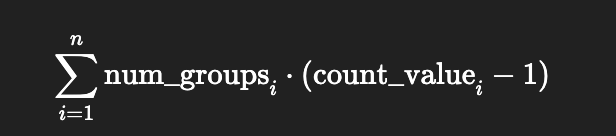

thì ta được `3564x(2-1)+1782x(3-1) = 7128 (đây chính là số records tăng lên so với trước khi merge với bộ holidays_events)`

=> *Điều này là vì trong cùng một ngày sẽ có hơn 1 event. Hãy kiểm chứng bên dưới*

**\- Sau khi kiểm tra thì tôi nhận ra là `với mỗi nhóm và có count > 1 thì nó sẽ rơi vào 2 nguyên nhân sau:`**

1. là `tất cả các cột từ holidays_events điều NaN`, thì nó thể hiện rằng ngày đó là ngày mà không có dữ liệu trong bảng holidays_events
2. là `tồn tại ít nhất một record trong nhóm có giá trị của các cột từ holidays_events`. Điều này là ngày đó sẽ có ít nhất 1 dữ liệu trong bảng holiday_events

**Giải pháp**:

1. `Xoá dupplicate và chỉ chừa lại 1 record cho mỗi nhóm.`
2. `Xoá các records không có giá trị cho các cột đến từ holidays_events cho mỗi nhóm.`


In [ ]:
date_handle_duplicate = df_filtered['date'].unique().to_numpy()
print(date_handle_duplicate)

In [ ]:
df_train_store_oil_holiday.info()

In [ ]:
# B1: Lọc các dòng có date nằm trong date_handle_duplicate
temp = df_train_store_oil_holiday[df_train_store_oil_holiday['date'].isin(date_handle_duplicate)]

# B2: Group theo 'date', 'store_nbr', 'family'
def handle_group(group):
    if group['locale_name'].isna().all():
        return group.iloc[[0]]
    else:
        return group[~group['locale_name'].isna()]

# B3: Áp dụng xử lý theo từng nhóm
processed = temp.groupby(['date', 'store_nbr', 'family'], group_keys=False).apply(handle_group).reset_index(drop=True)

# B4: Giữ lại các dòng có date không nằm trong date_handle_duplicate
remaining = df_train_store_oil_holiday[~df_train_store_oil_holiday['date'].isin(date_handle_duplicate)]

# B5: Gộp kết quả
df_train_store_oil_holiday = pd.concat([remaining, processed], ignore_index=True)


In [ ]:
# Duplicate
df_train_store_oil_holiday.duplicated().sum()

In [ ]:
# Số hàng có giá trị duy nhất
#len(df_train_store_oil_holiday.drop_duplicates(subset = ['date', 'store_nbr', 'family']))

In [ ]:
df_train_store_oil_holiday = df_train_store_oil_holiday.drop_duplicates(subset = ['date', 'store_nbr', 'family'])
df_train_store_oil_holiday.reset_index(drop = True, inplace = True)

In [ ]:
df_train_store_oil_holiday.info()

In [ ]:
# Xem thử các dòng trong group 'date', 'store_nbr', 'family' có phải là chứa dữ liệu từ holidays_events khác nhau không
df_grouped_after = df_train_store_oil_holiday.groupby(['date', 'store_nbr', 'family']).size().reset_index(name='count')
df_filtered_after = df_grouped_after[df_grouped_after['count'] > 1]
display(df_filtered_after)

In [ ]:
# Lấy cột đầu tiên để kiểm tra xem là sau khi chỉnh sửa thì đã giải quyết được vấn đề chưa.
df_train_store_oil_holiday[
    (df_train_store_oil_holiday['date'] == '2017-04-14') &
    (df_train_store_oil_holiday['store_nbr'] == 36) &
    (df_train_store_oil_holiday['family'] == 'POULTRY')
]

**`=> Nhận thấy rằng có những ngày mà tổ chức hơn 2 sự kiện có thể là sự kiện của cả nước lẫn khu vực.`**

## Xử lý transcation

In [ ]:
transactions.info()

In [ ]:
transactions[transactions['date'] > '2017-08-15']

\- transactions không có trong dữ liệu test là điều hiển nhiên vì dự đoán tương lai nên ta sẽ không có dữ liệu về số lần giao dịch. Nên ta sẽ xử lý bằng cách khác chứ không nên bỏ luôn thằng transaction.
giả sử như sử dụng lag feature,...

## 4. Hoàn tất Merging Data

In [ ]:
df_train_store_oil_holiday.to_csv('/kaggle/working/merge_train_store_oil_holiday.csv', index=False)

In [ ]:
df_test_store_oil_holiday.to_csv('/kaggle/working/merge_test_store_oil_holiday.csv', index=False)

In [ ]:
df_train_store_oil_holiday.info()

In [ ]:
# Những dòng bị null là do không phải ngày lễ (Không được ghi nhận trong holiday)
df_train_store_oil_holiday[df_train_store_oil_holiday['locale_name'].isnull()].head()

In [ ]:
df_test_store_oil_holiday.info()

# B. Feature Engineering

In [ ]:
# Copy để không ảnh hưởng gốc
df_train = df_train_store_oil_holiday.copy()
df_test = df_test_store_oil_holiday.copy()

# Tạo cột `sales` tạm thời cho test (toàn NaN)
df_test['sales'] = np.nan

# Gộp 2 bộ dữ liệu
df = pd.concat([df_train, df_test], ignore_index=True)
df = df.sort_values(by=['store_nbr', 'family', 'date'])

## 1. Xử lý missing values

In [ ]:
# Fillna cho các dòng không thuộc holiday là 0, vì ngày này không thuộc ngày lễ 
holiday_cols = ['locale_name', 'is_actual_holiday', 'is_calendar_holiday', 'is_work_day', 'is_transfer']
for col in holiday_cols:
    df[col] = df[col].fillna(0 if df[col].dtype in ['float64', 'int64'] else 'None')

# # Forward-fill giá dầu
# df['dcoilwtico'] = df['dcoilwtico'].fillna(method='ffill').fillna(method='bfill')

## 2. Phân rã trường date

In [ ]:
def create_date_features(dataframe):
    dataframe['month'] = dataframe.date.dt.month.astype("int8")
    dataframe['day'] = dataframe.date.dt.day.astype("int8")
    dataframe['dayofweek'] = dataframe.date.dt.dayofweek.astype("int8")
    dataframe['dayofyear'] = dataframe.date.dt.dayofyear.astype("int16")
    dataframe['weekofyear'] = dataframe.date.dt.isocalendar().week.astype("int8")
    return dataframe

df = create_date_features(df)

## 3. Tạo các Lag feature


In [ ]:
def create_lag_features(dataframe):
    lags = [16, 17, 28]
    for lag in lags:
        dataframe[f'sales_lag_{lag}'] = dataframe.groupby(['store_nbr', 'family'])['sales'].transform(
            lambda x: x.shift(lag)
        )
    return dataframe

df = create_lag_features(df)

## 4. Tạo các Rolling features

In [ ]:
def create_rolling_features(dataframe):
    windows = [7, 14, 28]
    for window in windows:
        dataframe[f'sales_rolling_mean_{window}'] = dataframe.groupby(['store_nbr', 'family'])['sales'].transform(
            lambda x: x.shift(16).rolling(window).mean()
        )
        dataframe[f'sales_rolling_std_{window}'] = dataframe.groupby(['store_nbr', 'family'])['sales'].transform(
            lambda x: x.shift(16).rolling(window).std()
        )
    return dataframe

df = create_rolling_features(df)

In [ ]:
df.info()

# C. Tiền xử lí

## 1. Xử lí missing values gây ra bởi quá trình tạo 2 thuộc tính lag và rolling 

In [ ]:
# Encode các cột object thành category
for col in df.select_dtypes('object').columns:
    df[col] = df[col].astype('category')

# Tách dữ liệu thành train và test
train = df[df['sales'].notna()].copy()
test = df[df['sales'].isna()].copy()

'''
# Tách dữ liệu thành train và test
train_final = df[df['sales'].notna()].copy()
test_final = df[df['sales'].isna()].copy()

# Áp dụng log transform cho biến target
train_final['sales'] = np.log1p(train_final['sales'])
'''

In [ ]:
train.isnull().sum()

In [ ]:
train.dropna(inplace=True)
train.reset_index(drop=True, inplace=True)
train.isnull().sum()

In [ ]:
train.info()

## 2. Xử lí outlier + log transformation 

### Chia dữ liệu thành train, val, test

In [ ]:
# Set date làm index,Chia tập train/val theo thời gian
train.set_index('date', inplace=True)
#y_train.index = train.index  # Đảm bảo y có cùng index với X
test.set_index('date', inplace=True)

val_start_date = pd.to_datetime("2017-08-01")

train_part = train[train.index < val_start_date]
val_part   = train[train.index >= val_start_date]

#y_train_part = y_train[y_train.index < val_start_date]
#y_val_part   = y_train[y_train.index >= val_start_date]
print(f"Kích thước của tập train là:{train_part.shape}")
#print(f"Kích thước của tập y_train là:{y_train_part.shape}")
print(f"Kích thước của tập val là:{val_part.shape}")
#print(f"Kích thước của tập y_val là:{y_val_part.shape}")
print(f"Kích thước của tập test là {test.shape}")

# Áp dụng log transform cho biến target
#train_final['sales'] = np.log1p(train_final['sales'])

### Xem xét phân phối dữ liệu 2 thuộc tính 'sales' và 'dcoilwtico'

In [ ]:
from scipy.stats import skew

# Tính skewness
skewness_value = train_part['sales'].skew()

# Vẽ biểu đồ phân phối và KDE
plt.figure(figsize=(10, 5))
sns.histplot(train_part['sales'], bins=50, kde=True, color='skyblue')
plt.title(f"Phân phối doanh thu (Skewness = {skewness_value:.2f})")
plt.xlabel("Doanh số")
plt.ylabel("Số lượng bản ghi")
plt.grid(True)
plt.show()

In [ ]:
plt.figure(figsize=(8, 4))
sns.boxplot(x=train_part['sales'], color='lightcoral')
plt.title("Boxplot doanh số trước khi xử lí outlier (sales)")
plt.xlabel("Sales")
plt.grid(True)
plt.show()

Phân phối cho thấy doanh thu bị lệch phải nặng, tiến hành xử lí outlier và log transformation

In [ ]:
# Tính skewness
skewness_value = train_part['dcoilwtico'].skew()

# Vẽ biểu đồ phân phối và KDE
plt.figure(figsize=(10, 5))
sns.histplot(train_part['dcoilwtico'], bins=50, kde=True, color='skyblue')
plt.title(f"Phân phối giá dầu (Skewness = {skewness_value:.2f})")
plt.xlabel("Giá dầu")
plt.ylabel("Số lượng bản ghi")
plt.grid(True)
plt.show()

In [ ]:
plt.figure(figsize=(8, 4))
sns.boxplot(x=train_part['dcoilwtico'], color='lightcoral')
plt.title("Boxplot giá dầu (dcoilwtico)")
plt.xlabel("Giá dầu")
plt.grid(True)
plt.show()

Phân phối giá dầu khá ổn định, theo phân phối chuẩn, lệch trái nhẹ nhưng không đáng kể, tuy nhiên vẫn áp dụng log transformation để cùng đơn vị đo và miền giá trị với thuộc tính 'sales'

In [ ]:
#Xử lí outlier + log transformation 
def compute_iqr_bounds(data, cols):
    """
    Tính ngưỡng IQR (lower, upper) cho từng cột dựa trên tập train.
    """
    bounds = {}
    for col in cols:
        Q1 = data[col].quantile(0.25)
        Q3 = data[col].quantile(0.75)
        IQR = Q3 - Q1
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR
        print(f"✅ Cột: {col} | Ngưỡng dưới: {lower_bound:.2f} | Ngưỡng trên: {upper_bound:.2f}")
        bounds[col] = (lower_bound, upper_bound)
    return bounds


def apply_iqr_clip(data, bounds):
    """
    Áp dụng clip giá trị theo IQR bounds đã tính.
    """
    data_clean = data.copy()
    for col, (lower, upper) in bounds.items():
        data_clean[col] = data_clean[col].clip(lower=lower, upper=upper)
    return data_clean


def apply_log_transform(data, cols):
    """
    Áp dụng log1p transform cho các cột được chỉ định.
    """
    data_transformed = data.copy()
    for col in cols:
        data_transformed[col] = np.log1p(data_transformed[col])
    return data_transformed


# 1️⃣ Tính ngưỡng IQR trên train_part — chỉ với 'sales'
cols_outlier_handle = ['sales']
iqr_bounds = compute_iqr_bounds(train_part, cols_outlier_handle)

# 2️⃣ Clip outliers cho cả 3 tập — chỉ với 'sales'
train_part_clean = apply_iqr_clip(train_part, iqr_bounds)
val_part_clean   = apply_iqr_clip(val_part, iqr_bounds)
test_clean       = apply_iqr_clip(test, iqr_bounds)

# 3️⃣ Áp dụng log1p transform cho cả 'sales' và 'dcoilwtico'
cols_log_transform = ['sales', 'dcoilwtico']
train_part_log = apply_log_transform(train_part_clean, cols_log_transform)
val_part_log   = apply_log_transform(val_part_clean, cols_log_transform)
test_log       = apply_log_transform(test_clean, cols_log_transform)


### Xem xét lại phân phối dữ liệu sau khi xử lí outlier + log transformation

In [ ]:
# Tính skewness
skewness_value = train_part_log['sales'].skew()

# Vẽ biểu đồ phân phối và KDE
plt.figure(figsize=(10, 5))
sns.histplot(train_part_log['sales'], bins=50, kde=True, color='skyblue')
plt.title(f"Phân phối doanh thu sau khi xử lí outlier + log transformation (Skewness = {skewness_value:.2f})")
plt.xlabel("Doanh số")
plt.ylabel("Số lượng bản ghi")
plt.grid(True)
plt.show()

In [ ]:
plt.figure(figsize=(8, 4))
sns.boxplot(x=train_part_log['sales'], color='lightcoral')
plt.title("Boxplot doanh số sau khi xử lí outlier + log transformation (sales)")
plt.xlabel("Sales")
plt.grid(True)
plt.show()

In [ ]:
# Tính skewness
skewness_value = train_part_log['dcoilwtico'].skew()

# Vẽ biểu đồ phân phối và KDE
plt.figure(figsize=(10, 5))
sns.histplot(train_part_log['dcoilwtico'], bins=50, kde=True, color='skyblue')
plt.title(f"Phân phối giá dầu sau khi log transformation (Skewness = {skewness_value:.2f})")
plt.xlabel("Giá dầu")
plt.ylabel("Số lượng bản ghi")
plt.grid(True)
plt.show()

In [ ]:
plt.figure(figsize=(8, 4))
sns.boxplot(x=train_part_log['dcoilwtico'], color='lightcoral')
plt.title("Boxplot giá dầu sau khi log tranformation(dcoilwtico)")
plt.xlabel("Giá dầu")
plt.grid(True)
plt.show()

## 3. Xác định biến và tạo ma trận đặc trưng

In [ ]:
# Xác định biến đặc trưng và biến mục tiêu
TARGET = 'sales'
features_to_drop = [TARGET, 'id']
features = [col for col in train_part_log.columns if col not in features_to_drop]

# Tạo X và y
X_train_part = train_part_log[features]
y_train_part = train_part_log[TARGET]
X_val_part = val_part_log[features]
y_val_part = val_part_log[TARGET]
X_test = test_log[features]

## 4. Thêm feature và xử lý thời gian

In [ ]:
# Thêm feature liên quan đến ngày lễ và ngày nhận lương
#X_train['is_New_Year'] = X_train['date'].dt.dayofyear == 1
#X_train['is_paid_day'] = (X_train['date'].dt.day == 15) | (X_train['date'].dt.is_month_end)

#X_test['is_New_Year'] = X_test['date'].dt.dayofyear == 1
#X_test['is_paid_day'] = (X_test['date'].dt.day == 15) | (X_test['date'].dt.is_month_end)

# Xoá cột date sau khi xử lý xong
'''
X_train.drop(['date'], axis=1, inplace=True)
X_test.drop(['date'], axis=1, inplace=True)
'''


# D. Huấn luyện mô hình

## 1. Hồi quy ElasticNet 

In [ ]:
X_train_part.info()

In [ ]:
X_test.info()

In [ ]:
cols_to_encode = ['city', 'state', 'family', 'type', 'locale_name']
X_train_part[cols_to_encode].nunique()

Nhận thấy số lượng giá trị unique ở các biến categorical khá ít, chúng ta sẽ sử dụng One-hot encoding để mã hóa các biến này về kiểu numeric

### Encode 'city', 'state', 'family', 'type', 'locale_name' với One-hot encoding


In [ ]:
### Encode với One-hot encoding
'''
X_train_encoded = pd.get_dummies(X_train_part, columns=cols_to_encode, drop_first=True)
X_val_encoded = pd.get_dummies(X_val_part, columns=cols_to_encode, drop_first=True)
X_test_encoded = pd.get_dummies(X_test, columns=cols_to_encode, drop_first=True)
X_train_encoded
'''

In [ ]:
# Khai báo encoder
ohe = OneHotEncoder(drop='first', handle_unknown='ignore', sparse=False)

# Fit trên tập train
X_train_ohe = ohe.fit_transform(X_train_part[cols_to_encode])

# Transform tập val & test theo cùng cấu trúc
X_val_ohe = ohe.transform(X_val_part[cols_to_encode])
X_test_ohe = ohe.transform(X_test[cols_to_encode])

# Biến thành DataFrame
ohe_cols = ohe.get_feature_names_out(cols_to_encode)
X_train_ohe = pd.DataFrame(X_train_ohe, columns=ohe_cols, index=X_train_part.index)
X_val_ohe = pd.DataFrame(X_val_ohe, columns=ohe_cols, index=X_val_part.index)
X_test_ohe = pd.DataFrame(X_test_ohe, columns=ohe_cols, index=X_test.index)

# Các cột số/thời gian... (không encode)
X_train_rest = X_train_part.drop(columns=cols_to_encode)
X_val_rest = X_val_part.drop(columns=cols_to_encode)
X_test_rest = X_test.drop(columns=cols_to_encode)

# Gộp lại
X_train_encoded = pd.concat([X_train_rest, X_train_ohe], axis=1)
X_val_encoded = pd.concat([X_val_rest, X_val_ohe], axis=1)
X_test_encoded = pd.concat([X_test_rest, X_test_ohe], axis=1)

In [ ]:
#Kiểm tra số cột giống nhau
set(X_train_encoded.columns) == set(X_val_encoded.columns) == set(X_test_encoded.columns)


In [ ]:
#Kiểm tra null
print("🔍 X_train_encoded có NaN:", X_train_encoded.isnull().values.any())
print("🔍 X_val_encoded có NaN:", X_val_encoded.isnull().values.any())
print("🔍 X_test_encoded có NaN:", X_test_encoded.isnull().values.any())

In [ ]:
X_train_encoded

In [ ]:
'''
#Chuẩn hóa dữ train, val, test với log transformed để giúp mô hình mau hội tụ hơn 
X_train_log = X_train_encoded.copy()
X_val_log = X_val_encoded.copy()
X_test_log = X_test_encoded.copy()

cols_to_log = [
    'sales_lag_16', 'sales_lag_17', 'sales_lag_28',
    'sales_rolling_mean_7', 'sales_rolling_std_7',
    'sales_rolling_mean_14', 'sales_rolling_std_14',
    'sales_rolling_mean_28', 'sales_rolling_std_28'
]

# Log1p-transform chỉ các cột này
for col in cols_to_log:
    X_train_log[col] = np.log1p(X_train_encoded[col])
    X_val_log[col]   = np.log1p(X_val_encoded[col])
    X_test_log[col]  = np.log1p(X_test_encoded[col])

print(f"Số chiều tập train X: {X_train_log.shape}")
print(f"Số chiều tập val X: {X_val_log.shape}")
print(f"Số chiều tập test X: {X_test_log.shape}")
#Chuẩn hóa biến mục tiêu
#y_scaler = StandardScaler()
#y_train_scaled = y_scaler.fit_transform(y_train_part.values.reshape(-1, 1)).ravel()
#y_val_scaled = y_scaler.transform(y_val_part.values.reshape(-1, 1)).ravel()
'''

In [ ]:
#Huấn luyện mô hình
model_elas = ElasticNet(alpha=0.01, l1_ratio=0.5, max_iter=10000, fit_intercept=True, random_state = 42) # alpha = 0.001, l1_ratio = 0.85
model_elas.fit(X_train_encoded, y_train_part)

#Dự đoán trên tập val
y_pred_scaled = model_elas.predict(X_val_encoded)

# Exp ngược lại (inverse log1p)
#y_pred_model_elas = np.exp(y_pred_scaled) - 1
#y_val_true = np.exp(y_val_part) - 1
# Đánh giá kết quả dự đoán
rmse_model1 = mean_squared_error(y_val_part, y_pred_scaled, squared=False)
print(f"📉 RMSE trên tập validation của ElasticNet: {rmse_model1:.4f}")

In [ ]:
y_pred_scaled

In [ ]:
'''
predictions_elastic = model_elas.predict(X_test_scaled)
predictions_elastic_inverse = y_scaler.inverse_transform(predictions_elastic.reshape(-1, 1)).flatten()

# Dự đoán test và xuất file 
submission = pd.DataFrame({
    'id': test_final['id'].values,
    'sales': predictions
})
submission.to_csv('submission_elasticnet.csv', index=False)
print("\n✅ Done! File `submission_elasticnet.csv` đã được lưu.")
'''

### Sử dụng ElasticNetCV 

In [ ]:
from sklearn.linear_model import ElasticNetCV
from sklearn.model_selection import TimeSeriesSplit

tscv = TimeSeriesSplit(n_splits=5)

model_cv = ElasticNetCV(
    alphas=[0.01, 0.1, 1.0],
    l1_ratio=[0.1, 0.5, 0.75, 1.0],
    cv=tscv,
    max_iter=10000,
    fit_intercept=True, #Ban đầu để là false chạy ổn
    n_jobs=-1,
    random_state=42
)

# Huấn luyện
model_cv.fit(X_train_encoded, y_train_part)

In [ ]:
from sklearn.metrics import mean_squared_log_error


In [ ]:
# Tính RMSLE từ mse_path_
# Vì target đã log1p trước khi train, nên RMSE trên log-scale chính là RMSLE trên giá trị thực
rmsle_matrix = np.sqrt(model_cv.mse_path_.mean(axis=2))  # shape: (n_l1_ratio, n_alpha)

# Lấy danh sách alpha và l1_ratio thực tế đã fit
alphas = model_cv.alphas
l1_ratios = model_cv.l1_ratio

# Tìm index của giá trị RMSLE nhỏ nhất
min_idx = np.unravel_index(np.argmin(rmsle_matrix), rmsle_matrix.shape)
best_l1_ratio = l1_ratios[min_idx[0]]
best_alpha = alphas[min_idx[1]]

print("✅ L1_ratio tốt nhất theo RMSLE nhỏ nhất:", best_l1_ratio)
print("✅ Alpha tốt nhất theo RMSLE nhỏ nhất:", best_alpha)
print(f"📉 RMSLE nhỏ nhất: {rmsle_matrix[min_idx]:.4f}")

# Chuyển về DataFrame
rmsle_df = pd.DataFrame(
    rmsle_matrix,
    index=[f"L1={r}" for r in l1_ratios],
    columns=[f"α={a}" for a in alphas]
)

# Vẽ heatmap RMSLE
plt.figure(figsize=(10, 6))
sns.heatmap(rmsle_df, annot=True, fmt=".4f", cmap="YlGnBu", cbar_kws={'label': 'RMSLE'})
plt.title("RMSLE theo từng Alpha và L1 Ratio trong ElasticNetCV")
plt.xlabel("Alpha")
plt.ylabel("L1 Ratio")
plt.tight_layout()
plt.show()


In [ ]:
# --- Bước 1: Scale dữ liệu val ---

# --- Bước 2: Dự đoán ---
y_pred_log = model_cv.predict(X_val_encoded)

# --- Bước 3: Chuyển ngược log1p-transform ---
#y_pred = np.expm1(y_pred_log)
#y_val_true = np.expm1(y_val_part)
y_pred = y_pred_log
y_val_true = y_val_part

# --- Bước 4: Tạo Series có index là thời gian ---
y_pred_series = pd.Series(y_pred, index=X_val_log.index, name="y_pred")
y_true_series = pd.Series(y_val_true, index=X_val_log.index, name="y_true")  # nhớ exp ngược y_true nữa nếu đã log trước đó

# --- Bước 5: Tính tổng doanh số mỗi ngày ---
y_true_daily = y_true_series.groupby(y_true_series.index.date).sum()
y_pred_daily = y_pred_series.groupby(y_pred_series.index.date).sum()

# Đưa index về DatetimeIndex
y_true_daily.index = pd.to_datetime(y_true_daily.index)
y_pred_daily.index = pd.to_datetime(y_pred_daily.index)

# --- Bước 6: Tính RMSE ---
rmse_daily = mean_squared_error(y_true_daily, y_pred_daily, squared=False)

# --- Bước 7: Vẽ biểu đồ ---
plt.figure(figsize=(14, 5))
plt.plot(y_true_daily, label="Tổng doanh số thực tế", color='blue')
plt.plot(y_pred_daily, label="Tổng doanh số dự đoán", color='orange', linestyle='--')
plt.title("So sánh tổng doanh số mỗi ngày trên tập Validation (ElasticNetCV)")
plt.xlabel("Ngày")
plt.ylabel("Tổng doanh số")
plt.legend()
plt.grid(True)

# In RMSE lên biểu đồ

plt.text(
    0.01, 0.95,
    f"RMSLE: {rmse_daily:.2f}",
    transform=plt.gca().transAxes,
    fontsize=12,
    bbox=dict(boxstyle="round", facecolor="lightyellow", edgecolor="gray")
)
plt.tight_layout()
plt.show()




In [ ]:
# --- Bước 1: Scale dữ liệu val ---
# X_val_log đã log-transform từ trước (giữ nguyên)

# --- Bước 2: Dự đoán ---
y_pred_scaled = model_cv.predict(X_val_log)

# --- Bước 3: Chuyển ngược log1p-transform (nếu y đã log1p khi train thì phải expm1 ngược lại) ---
# Ví dụ nếu target đã log1p khi huấn luyện:
y_pred = y_pred_scaled
y_true = y_val_part

# --- Bước 4: Tạo Series có index là thời gian ---
y_pred_series = pd.Series(y_pred, index=X_val_part.index, name="y_pred")
y_true_series = pd.Series(y_true, index=X_val_part.index, name="y_true")

# --- Bước 5: Tính tổng doanh số mỗi ngày ---
y_true_daily = y_true_series.groupby(y_true_series.index.date).sum()
y_pred_daily = y_pred_series.groupby(y_pred_series.index.date).sum()

# Đưa index về DatetimeIndex
y_true_daily.index = pd.to_datetime(y_true_daily.index)
y_pred_daily.index = pd.to_datetime(y_pred_daily.index)

# --- Bước 6: Tính RMSLE ---
# RMSLE yêu cầu giá trị >= 0 — nếu dữ liệu có thể âm thì cần xử lý trước khi log
# (với doanh số chắc chắn >= 0 nên không cần)

rmsle_daily = mean_squared_error(y_true_daily, y_pred_daily, squared=False)

# --- Bước 7: Vẽ biểu đồ ---
plt.figure(figsize=(14, 5))
plt.plot(y_true_daily, label="Tổng doanh số thực tế", color='blue')
plt.plot(y_pred_daily, label="Tổng doanh số dự đoán", color='orange', linestyle='--')
plt.title("So sánh tổng doanh số mỗi ngày trên tập Validation (ElasticNetCV)")
plt.xlabel("Ngày")
plt.ylabel("Tổng doanh số")
plt.legend()
plt.grid(True)

# In RMSLE lên biểu đồ
plt.text(
    0.01, 0.95,
    f"RMSLE: {rmsle_daily:.4f}",
    transform=plt.gca().transAxes,
    fontsize=12,
    bbox=dict(boxstyle="round", facecolor="lightyellow", edgecolor="gray")
)

plt.tight_layout()
plt.show()


In [ ]:
y_val_part

In [ ]:
pd.set_option('display.max_columns', None)

# Note: đã tắt chuyển đổi log ở bước tiền xử lí và sử dụng StandardScaler để thay thế

In [ ]:
# Gộp hai series thành DataFrame
df_output = pd.DataFrame({
    "true_values": y_true_series,
    "predicted_values": y_pred_series
})

# Xuất ra file CSV
df_output.to_csv("validation_predictions_ElasticNetCV.csv")

In [ ]:
'''
# Số lượng mẫu train ban đầu
n_train = len(X_train_encoded)

# Lấy lại validation
X_val_scaled = X_full_scaled[n_train:]
y_val = y_full[n_train:]
# Dự đoán
y_pred_scaled = model_cv.predict(X_val_scaled)

# Chuyển ngược chuẩn hóa
y_pred = y_scaler.inverse_transform(y_pred_scaled.reshape(-1, 1)).ravel()
y_val_true = y_val.values  # Vì y_val vẫn còn nguyên dạng gốc
#Vẽ biểu đồ
# Vẽ n điểm cuối cùng để dễ quan sát
n_plot = 800
plt.figure(figsize=(14, 5))
plt.plot(y_val_true[-n_plot:], label="Giá trị thực tế", color='blue')
plt.plot(y_pred[-n_plot:], label="Dự đoán ElasticNetCV", color='orange', linestyle='--')
plt.title(f"Dự đoán giá sản phẩm trên tập Validation ({n_plot} điểm cuối)")
plt.xlabel("Thời gian (index)")
plt.ylabel("Giá sản phẩm")
plt.legend()
plt.tight_layout()
plt.grid(True)
plt.show()
'''

In [ ]:
pd.set_option('display.max_columns', None)

In [ ]:
X_test_log

In [ ]:
# Dự đoán
predictions_elastic_log = model_cv.predict(X_test_log)

# Chuyển ngược log1p-transform
predictions_elastic = np.expm1(predictions_elastic_log)

# Tạo submission và lưu file
submission = pd.DataFrame({
    'id': test_final['id'].values,
    'sales': predictions_elastic
})

submission.to_csv('submission_elasticnet.csv', index=False)
print("\n✅ Done! File `submission_elasticnet.csv` đã được lưu.")


In [ ]:
submission

## 2. ARIMA - SARIMAX

## 3. Ensemble learning

### LightGBM

In [ ]:
model_lgb = lgb.LGBMRegressor(
    objective='regression_l1',
    metric='rmse',
    n_estimators=2000,
    learning_rate=0.01,
    feature_fraction=0.8,
    bagging_fraction=0.8,
    bagging_freq=1,
    n_jobs=-1,
    seed=42,
)

model_lgb.fit(
    X_train_part, y_train_part,
    eval_set=[(X_val_part, y_val_part)],
    eval_metric='rmse',
    callbacks=[lgb.early_stopping(100, verbose=True)]
)

In [ ]:
# Dự đoán log
predictions_log = model_lgb.predict(X_test, num_iteration=model_lgb.best_iteration_)

# Biến đổi ngược log1p
predictions = np.expm1(predictions_log)
predictions[predictions < 0] = 0

# Xuất file
submission = pd.DataFrame({
    'id': test_final['id'].values,
    'sales': predictions
})
submission.to_csv('submissio_lightgbm.csv', index=False)
print("\n✅ Done! File `submission_lightgbm.csv` đã được lưu.")

### Cat boost

In [ ]:
cat_features = [col for col in X_train.columns if str(X_train[col].dtype) in ['category', 'object']]
print(f"Các cột categorical sẽ được CatBoost xử lý trực tiếp: {cat_features}")

In [ ]:
val_start_date = '2017-08-01'
train_mask = train_final['date'] < val_start_date
val_mask = train_final['date'] >= val_start_date

X_train_part = X_train[train_mask]
y_train_part = y_train[train_mask]
X_val_part = X_train[val_mask]
y_val_part = y_train[val_mask]

In [ ]:
catboost_model = CatBoostRegressor(
    iterations=2000,
    learning_rate=0.05,
    depth=8,
    loss_function='RMSE',
    eval_metric='RMSE',
    random_seed=42,
    verbose=100,
    early_stopping_rounds=100,
    task_type="CPU"
)

print("🐱 Đang huấn luyện CatBoost...")

catboost_model.fit(
    X_train_part, y_train_part,
    eval_set=(X_val_part, y_val_part),
    cat_features=cat_features,
    use_best_model=True
)


In [ ]:
# Dự đoán trên validation
val_preds_log = catboost_model.predict(X_val_part)
rmse_cb = mean_squared_error(y_val_part, val_preds_log, squared=False)
print(f"📉 RMSE trên tập validation (log sales) của CatBoost: {rmse_cb:.4f}")


In [ ]:
# Dự đoán test
predictions_log = catboost_model.predict(X_test)

# Ngược log
predictions = np.expm1(predictions_log)
predictions[predictions < 0] = 0

submission_cb = pd.DataFrame({
    'id': test_final['id'].values,
    'sales': predictions
})

submission_cb.to_csv('submission_catboost.csv', index=False)
print("✅ Done! File `submission_catboost.csv` đã được lưu.")
